# Intro

Hello to my first jupyter notebook machine learning exercise.

Lets first load the basic's. 
The exlamation mark makes you run a command in shell. Below is for **colab**.
`! [ -e /content] && pip install -Uqq fastbook`


In [7]:
import multiprocessing as mp
mp.set_start_method('fork', force=True)
from fastai.vision.widgets import *
from fastai.vision.all import *


In [4]:
import shutil, requests, time
from fastai.vision.all import *

path = Path('mushrooms')
shutil.rmtree(path, ignore_errors=True)   # deletes the old DuckDuckGo images

def inat_photo_urls(taxon, n=300):
    urls, page = [], 1
    while len(urls) < n:
        r = requests.get('https://api.inaturalist.org/v1/observations', params={
            'taxon_name': taxon,
            'quality_grade': 'research',
            'photos': 'true',
            'per_page': 200,
            'page': page})
        results = r.json()['results']
        if not results: break
        for obs in results:
            urls.append(obs['photos'][0]['url'].replace('square', 'medium'))
        page += 1
        time.sleep(1)
    return urls[:n]

mushroom_types = 'Amanita phalloides', 'Amanita muscaria', 'Russula xerampelina'

for o in mushroom_types:
    dest = path/o
    dest.mkdir(parents=True, exist_ok=True)
    print(f'Downloading {o}...')
    download_images(dest, urls=inat_photo_urls(o, 300))

failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
for d in path.ls(): print(d.name, len(get_image_files(d)))


Amanita phalloides 300
Amanita muscaria 300
Russula xerampelina 299


Now lets indentify the top 3 most dangerous mushrooms. First we search the images

In [3]:
fns = get_image_files(path)
fns

NameError: name 'path' is not defined

In [ ]:
failed = verify_images(fns)
failed

In [7]:
failed.map(Path.unlink)

[]

In [8]:
verify_images(fns)


[]

In [9]:
class DataLoaders(GetAttr):
    def __init__(self, *loaders): self.loaders=loaders
    def __getitem__(self,i): return self.loaders[i]
    train,valid = add_props(lambda i,self: self[i])

In [10]:
mushrooms = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=RandomResizedCrop(128, min_scale=(0.3))
    )

In [11]:
path = Path('mushrooms')
dls = mushrooms.dataloaders(path)

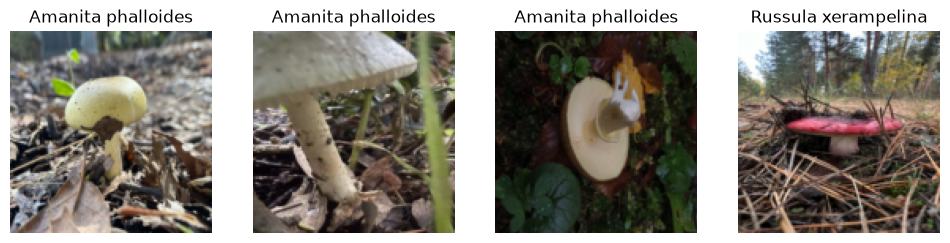

In [7]:
dls.valid.show_batch(max_n=4, nrows=1)


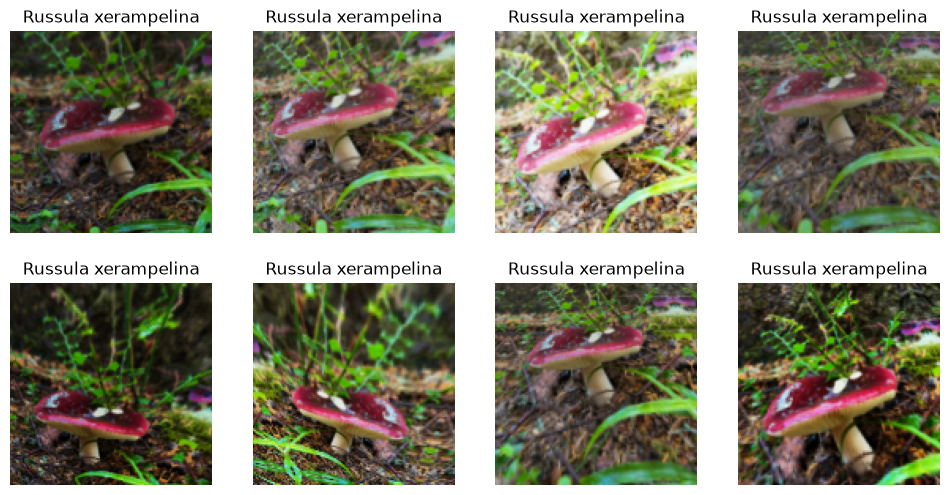

In [8]:
mushrooms = mushrooms.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = mushrooms.dataloaders(path)
dls.train.show_batch(max_n=8, nrows=2, unique=True)


In [ ]:
mushroomsbookmushrooms = mushrooms.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms())
dls = mushrooms.dataloaders(path,bs=4, num_workers=0)
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)


epoch,train_loss,valid_loss,error_rate,time
0,0.962836,0.527645,0.134831,00:43


epoch,train_loss,valid_loss,error_rate,time
0,0.831407,0.406482,0.123596,01:11
1,0.815810,0.327096,0.101124,01:05


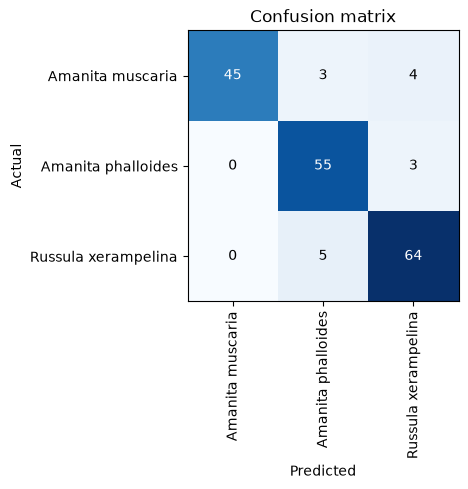

In [16]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

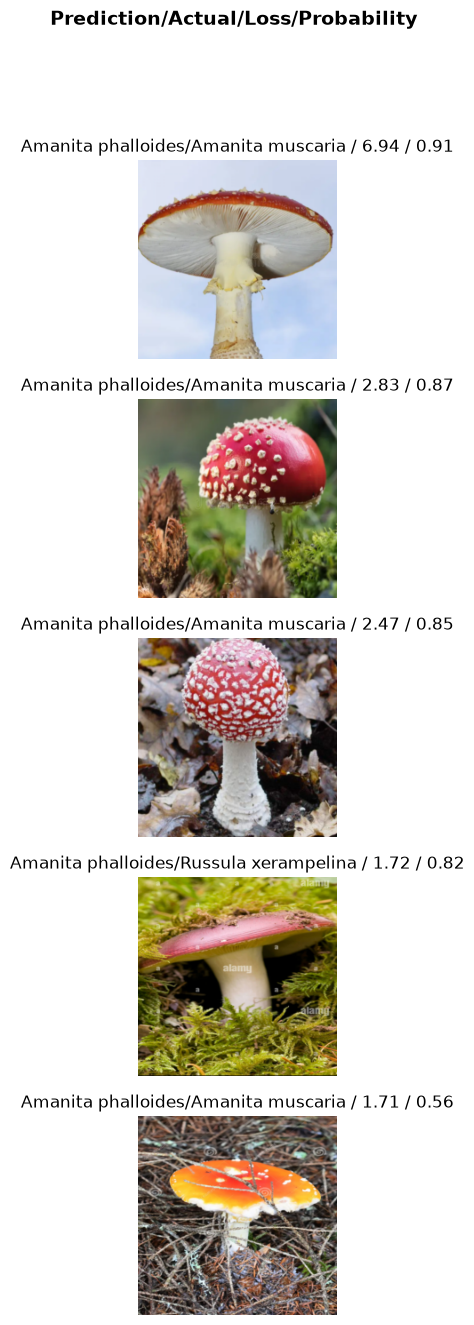

In [15]:
interp.plot_top_losses(5, nrows=5)


In [10]:
cleaner =  ImageClassifierCleaner(learn)
cleaner

In [17]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()

In [18]:
for idx,cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)

In [19]:
learn.export()

In [12]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

In [17]:
learn_inf=load_learner(path/'/home/mausz/code/fastai/mushroom/export.pkl')
learn_inf.predict('/home/mausz/code/fastai/mushroom/mushrooms/Amanita muscaria/ff9f1e49-943a-4aa1-91a9-079832d201da.jpg')

('Amanita muscaria', tensor(0), tensor([0.9815, 0.0160, 0.0025]))

In [22]:
learn_inf.dls.vocab

['Amanita muscaria', 'Amanita phalloides', 'Russula xerampelina']

In [23]:
#hide output
btn_upload = widgets.FileUpload()
btn_upload

FileUpload(value={}, description='Upload')

In [24]:
btn_upload = SimpleNamespace(data = ['/home/mausz/code/fastai/mushroomsbook/mushrooms/Amanita muscaria/46585c39-1c3b-4080-9cf9-afddac9c7851.jpg'])

In [25]:
img= PILImage.create(btn_upload.data[-1])

In [26]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

In [27]:
pred,pred_idx,probs = learn_inf.predict(img)

In [14]:
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probality: {probs[pred_idx]:.04f}'
lbl_pred

NameError: name 'pred' is not defined

In [29]:
btn_run = widgets.Button(description='Classify')
btn_run

Button(description='Classify', style=ButtonStyle())

In [30]:
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred,pred_idx,probs = learn_inf.predict(img)
    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'

btn_run.on_click(on_click_classify)

In [31]:
btn_upload = widgets.FileUpload()

In [32]:
VBox([widgets.Label('Select you mushroom'),
      btn_upload,btn_run,out_pl,lbl_pred])

In [33]:
%pip install voila
!jupyter server extension enable --sys-prefix voila.server_extension



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Enabling: voila.server_extension
- Writing config: /home/mausz/code/fastai/.venv/etc/jupyter
    - Validating voila.server_extension...
      voila.server_extension  OK
    - Extension successfully enabled.


In [ ]:
import sys; print(sys.executable)
!which pip jupyter

In [ ]:
!head -1 /home/mausz/code/fastai/.venv/bin/jupyter
!python -c "import voila, importlib; [importlib.import_module(p['module']) for p in voila._jupyter_server_extension_points()]"